In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from PIL import Image
from sklearn.preprocessing import OneHotEncoder , StandardScaler
import cv2
from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import datasets
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,LSTM, Embedding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, f1_score, accuracy_score
from sklearn.model_selection import cross_val_score , GridSearchCV
from xgboost import XGBRegressor

# Face Mask Detection

In [4]:
!pip install kaggle

In [5]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [6]:
# API to fetch the dataset from Kaggle
!kaggle datasets download -d omkargurav/face-mask-dataset

Dataset URL: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset
License(s): unknown
face-mask-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [7]:
from zipfile import ZipFile
dataset = '/content/face-mask-dataset.zip'

with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [8]:
!ls

confusion_matrix.png  face-mask-dataset.zip  sample_data
data		      face_mask_model.keras


## image preprocessing

In [9]:
mask_file = os.listdir("/content/data/with_mask")
print(len(mask_file))
print(mask_file[0:5])
print(mask_file[-5:])

3725
['with_mask_2112.jpg', 'with_mask_2382.jpg', 'with_mask_2572.jpg', 'with_mask_490.jpg', 'with_mask_841.jpg']
['with_mask_3688.jpg', 'with_mask_2679.jpg', 'with_mask_1584.jpg', 'with_mask_2932.jpg', 'with_mask_2754.jpg']


In [10]:
no_mask_file = os.listdir("/content/data/without_mask")
print(len(no_mask_file))
print(no_mask_file[0:5])
print(no_mask_file[-5:])

3828
['without_mask_2898.jpg', 'without_mask_421.jpg', 'without_mask_461.jpg', 'without_mask_2644.jpg', 'without_mask_3478.jpg']
['without_mask_1087.jpg', 'without_mask_1683.jpg', 'without_mask_384.jpg', 'without_mask_3211.jpg', 'without_mask_3360.jpg']


Create Labels for images

With Mask--->1

without --->0

In [11]:
with_mask = [1]*3725

without_mask = [0]*3828

In [12]:
print(with_mask[0:5])
print(without_mask[0:5],'\n')
print(len(without_mask),'\n')
print(len(with_mask))

[1, 1, 1, 1, 1]
[0, 0, 0, 0, 0] 

3828 

3725


In [13]:
labels = with_mask + without_mask

print(len(labels),'\n')
print(labels[0:5],'\n')
print(labels[-5:])

7553 

[1, 1, 1, 1, 1] 

[0, 0, 0, 0, 0]


Displaying Image

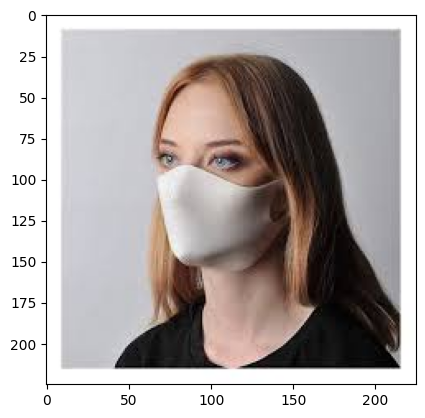

In [14]:
img = mpimg.imread("/content/data/with_mask/with_mask_773.jpg")
image = plt.imshow(img)
plt.show()

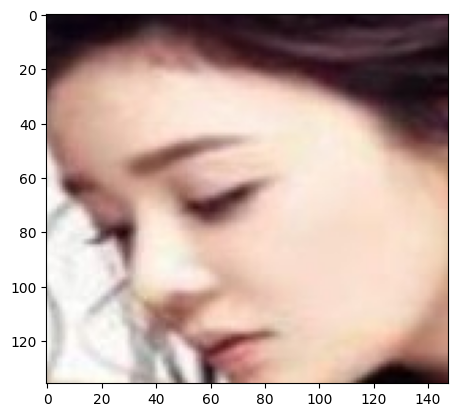

In [15]:
img = mpimg.imread("/content/data/without_mask/without_mask_3311.jpg")
image = plt.imshow(img)
plt.show()

# different size image

In [16]:
with_mask_path = "/content/data/with_mask/"

data =[]

for img in mask_file:
  image = Image.open(with_mask_path + img )
  image = image.resize((128,128))
  image = image.convert('RGB')
  image = np.array(image)
  data.append(image)


# for without mask image
without_mask_path = "/content/data/without_mask/"
for img in no_mask_file:
  image = Image.open(without_mask_path + img )
  image = image.resize((128,128))
  image = image.convert('RGB')
  image = np.array(image)
  data.append(image)




/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [17]:
len(data)

7553

In [18]:
type(data)

list

array([[[225, 225, 225],
        [225, 225, 225],
        [225, 225, 225],
        ...,
        [209, 209, 211],
        [209, 209, 211],
        [209, 209, 211]],

       [[225, 225, 225],
        [225, 225, 225],
        [225, 225, 225],
        ...,
        [209, 209, 211],
        [209, 209, 211],
        [209, 209, 211]],

       [[225, 225, 225],
        [225, 225, 225],
        [225, 225, 225],
        ...,
        [209, 209, 211],
        [209, 209, 211],
        [209, 209, 211]],

       ...,

       [[210, 210, 210],
        [210, 210, 210],
        [210, 210, 210],
        ...,
        [211, 210, 210],
        [209, 210, 209],
        [209, 209, 209]],

       [[210, 210, 210],
        [210, 210, 210],
        [210, 210, 210],
        ...,
        [211, 210, 210],
        [209, 210, 209],
        [208, 208, 208]],

       [[210, 210, 210],
        [210, 210, 210],
        [210, 210, 210],
        ...,
        [211, 210, 210],
        [209, 210, 209],
        [208, 208, 208]]], dtype=uint8)
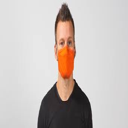

In [19]:
data[0]

In [20]:
print(type(data[0]))
print(data[0].shape)

<class 'numpy.ndarray'>
(128, 128, 3)


In [21]:
type(data[0])

numpy.ndarray

In [22]:
# converting labels and data list into numpy array
y = np.array(labels)
x = np.array(data)

In [23]:
print(type(x))
print(type(y))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [24]:
print(x.shape)
print(y.shape)

(7553, 128, 128, 3)
(7553,)


## Split data

In [25]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.1, random_state=42, stratify=y)

In [26]:
print(x_train.shape, y_train.shape, x_test.shape,y_test.shape)

(6797, 128, 128, 3) (6797,) (756, 128, 128, 3) (756,)


In [27]:
# scalling the data
x_train = x_train/255
x_test = x_test/255

## Build CNN

In [28]:
num_class =2

model = keras.Sequential()
model.add(keras.layers.Conv2D(32,(3,3),activation='relu',input_shape=(128,128,3)))
model.add(keras.layers.BatchNormalization(momentum=0.9))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Conv2D(64,(3,3),activation='relu'))
model.add(keras.layers.BatchNormalization(momentum=0.9))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Conv2D(128,(3,3),activation='relu'))
model.add(keras.layers.BatchNormalization(momentum=0.9))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(128,activation='relu'))
model.add(keras.layers.Dropout(0.5))

model.add(keras.layers.Dense(64,activation='relu'))
model.add(keras.layers.Dropout(0.5))

model.add(keras.layers.Dense(num_class, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [29]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [30]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,313,922 (12.64 MB)

 Trainable params: 3,313,474 (12.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [31]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5,
                               restore_best_weights=True)

history = model.fit(x_train, y_train, validation_split=0.1,
                    batch_size=64, epochs=30,
                    callbacks=[early_stopping])

Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 233s 2s/step - accuracy: 0.7907 - loss: 0.6507 - val_accuracy: 0.9074 - val_loss: 0.2284
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 250s 2s/step - accuracy: 0.8532 - loss: 0.3632 - val_accuracy: 0.9044 - val_loss: 0.2160
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 228s 2s/step - accuracy: 0.8869 - loss: 0.2828 - val_accuracy: 0.9235 - val_loss: 0.2010
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 224s 2s/step - accuracy: 0.9029 - loss: 0.2451 - val_accuracy: 0.9250 - val_loss: 0.1659
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.9076 - loss: 0.2307 - val_accuracy: 0.9324 - val_loss: 0.1467
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 227s 2s/step - accuracy: 0.9099 - loss: 0.2052 - val_accuracy: 0.9353 - val_loss: 0.1599
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 233s 2s/step - accuracy: 0.9263 - loss: 0.1725 - val_accuracy: 0.9397 - val_loss: 0.1427
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - accuracy: 0.9331 - loss: 0.1666 - val_accuracy: 0.9382 - v

24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 199ms/step
              precision    recall  f1-score   support

without_mask      0.956     0.969     0.962       383
   with_mask      0.967     0.954     0.961       373

    accuracy                          0.962       756
   macro avg      0.962     0.962     0.962       756
weighted avg      0.962     0.962     0.962       756



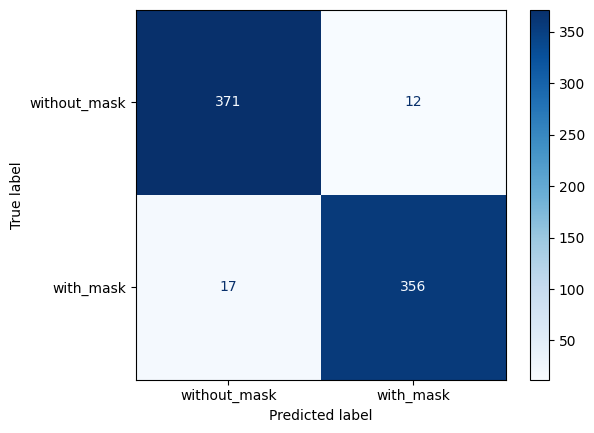

In [32]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

probs = model.predict(x_test)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_test, y_pred,
                            target_names=['without_mask', 'with_mask'], digits=3))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['without_mask', 'with_mask']).plot(cmap='Blues')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

model.save('face_mask_model.keras')

In [33]:
# model evalution
loss , accuracy = model.evaluate(x_test,y_test)
print(loss,'\n')
print(accuracy,)

24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 202ms/step - accuracy: 0.9616 - loss: 0.1426
0.14260537922382355 

0.9616402387619019


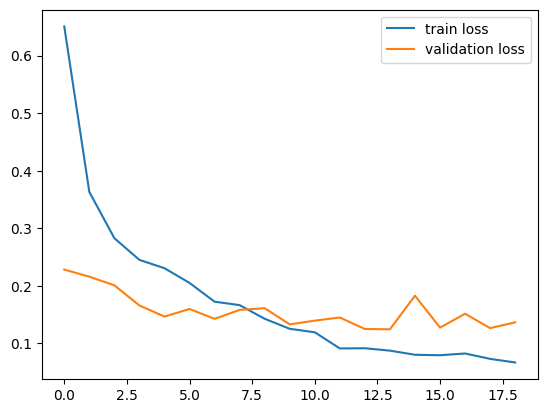

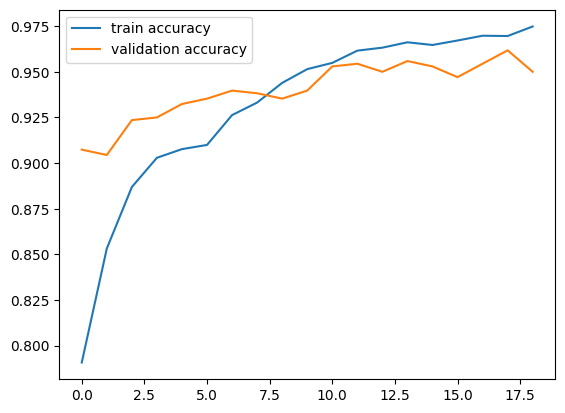

In [34]:
h = history

# plot the loss value
plt.plot(h.history['loss'], label='train loss')
plt.plot(h.history['val_loss'], label='validation loss')
plt.legend()
plt.show()

# plot the accuracy value
plt.plot(h.history['accuracy'], label='train accuracy')
plt.plot(h.history['val_accuracy'], label='validation accuracy')
plt.legend()
plt.show()

## Predictive System

In [35]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def predict_mask(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    faces = face_cascade.detectMultiScale(gray, 1.05, 3, minSize=(30, 30))

    results = []
    if len(faces) == 0:
        # No face found: treat the whole image as one face crop
        face = cv2.resize(rgb, (128, 128)) / 255.0
        p = model.predict(face[None], verbose=0)[0]
        label = 'Mask' if np.argmax(p) == 1 else 'No Mask'
        h, w = rgb.shape[:2]
        results.append(((0, 0, w, h), label, float(p.max())))
    else:
        for (x, y, w, h) in faces:
            face = cv2.resize(rgb[y:y+h, x:x+w], (128, 128)) / 255.0
            p = model.predict(face[None], verbose=0)[0]
            label = 'Mask' if np.argmax(p) == 1 else 'No Mask'
            results.append(((x, y, w, h), label, float(p.max())))
    return results

In [39]:
image_path = '/content/data/with_mask/with_mask_1111.jpg'
img_bgr = cv2.imread(image_path)

# Make the prediction
result = predict_mask(img_bgr)
result

[((0, 0, 74, 103), 'Mask', 0.9158148765563965)]